# Exercise 1 — Exploratory Data Analysis & Automated Reporting

**Author:** Mayank Mishra  
**Date:** 21 November 2026  
**Environment:** Python 3.12, Jupyter Notebook

## Objective

Create a reproducible random dataset, explore it visually, derive a row-wise
summary feature, and export the final table to Excel for automated reporting.

## Tasks

1. Generate a DataFrame with four random integer features (`f1`–`f4`).
2. Create a scatter plot of `f2` against `f3`.
3. Calculate the row-wise mean of `f1`–`f4` and store it in `f5`.
4. Export all five columns to an Excel workbook.

## Expected outputs

- `outputs/Exercise1/scatter_plot.png`
- `outputs/Exercise1/Exercise1_output.xlsx`

## 1. Import libraries and configure output paths

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

PROJECT_ROOT = Path.cwd()
OUTPUT_DIR = PROJECT_ROOT / "outputs" / "Exercise1"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)

print(f"Project root : {PROJECT_ROOT}")
print(f"Output folder: {OUTPUT_DIR}")
print(f"pandas {pd.__version__} | numpy {np.__version__}")

Project root : C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project
Output folder: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise1
pandas 3.0.5 | numpy 2.5.1


## 2. Generate the random DataFrame

In [2]:
df = pd.DataFrame({
    "f1": np.random.randint(10, 100, size=100),
    "f2": np.random.randint(10, 100, size=100),
    "f3": np.random.randint(10, 100, size=100),
    "f4": np.random.randint(10, 100, size=100),
})

print(f"DataFrame shape: {df.shape}")
df.head()

DataFrame shape: (100, 4)


,f1,f2,f3,f4
0,61,98,11,17
1,24,80,12,16
2,81,18,65,76
3,70,97,90,26
4,30,10,68,42


## 3. Scatter plot of f2 versus f3

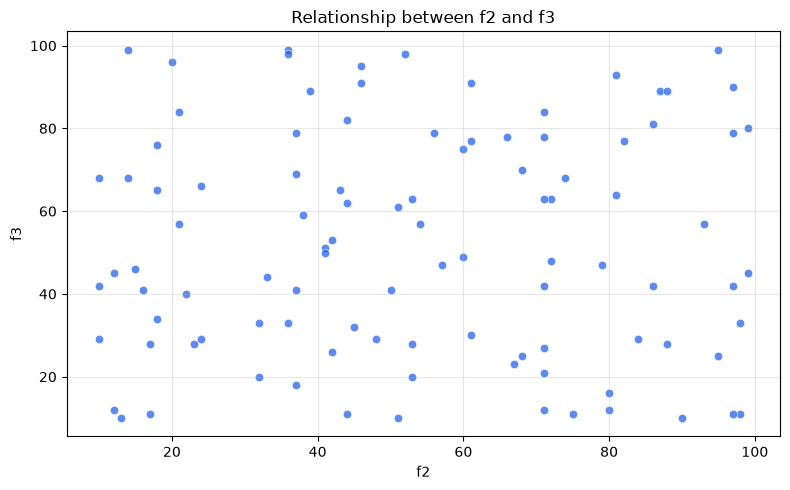

Saved: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise1\scatter_plot.png


In [3]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(
    df["f2"],
    df["f3"],
    color="#2563eb",
    alpha=0.75,
    edgecolor="white",
    linewidth=0.5,
)
ax.set_xlabel("f2")
ax.set_ylabel("f3")
ax.set_title("Relationship between f2 and f3")
ax.grid(True, alpha=0.3)

fig.tight_layout()
scatter_path = OUTPUT_DIR / "scatter_plot.png"
fig.savefig(scatter_path, dpi=150, bbox_inches="tight")
plt.show()
print(f"Saved: {scatter_path}")

## 4. Calculate the row-wise mean in f5

In [4]:
df["f5"] = df[["f1", "f2", "f3", "f4"]].mean(axis=1)
df.head()

,f1,f2,f3,f4,f5
0,61,98,11,17,46.75
1,24,80,12,16,33.00
2,81,18,65,76,60.00
3,70,97,90,26,70.75
4,30,10,68,42,37.50


## 5. Descriptive statistics

In [5]:
correlation = df["f2"].corr(df["f3"])
print(f"Pearson correlation between f2 and f3: {correlation:.3f}")
df.describe().round(2)

Pearson correlation between f2 and f3: 0.020


,f1,f2,f3,f4,f5
count,100.00,100.00,100.00,100.00,100.00
mean,56.68,53.74,51.91,51.86,53.55
std,27.28,27.11,27.26,23.39,13.94
min,11.00,10.00,10.00,11.00,28.50
25%,31.00,35.25,28.75,33.00,44.00
50%,60.50,52.50,48.50,52.50,51.88
75%,80.25,74.25,77.00,69.25,63.38
max,99.00,99.00,99.00,99.00,85.00


## 6. Export the complete table to Excel

In [6]:
excel_path = OUTPUT_DIR / "Exercise1_output.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:
    df.to_excel(writer, sheet_name="Data", index=False)
    df.describe().round(2).to_excel(writer, sheet_name="Summary")

print(f"Saved: {excel_path}")
print(f"File size: {excel_path.stat().st_size:,} bytes")

pd.read_excel(excel_path, sheet_name="Data").head()

Saved: C:\Users\hp\Desktop\dev\nielit\exercises\Practical_Laboratory_Project\outputs\Exercise1\Exercise1_output.xlsx
File size: 8,098 bytes


,f1,f2,f3,f4,f5
0,61,98,11,17,46.75
1,24,80,12,16,33.00
2,81,18,65,76,60.00
3,70,97,90,26,70.75
4,30,10,68,42,37.50


## Conclusion

- A reproducible 100-row DataFrame containing four random integer features
  (`f1`–`f4`) was generated with `numpy.random.seed(42)`.
- The scatter plot gives a visual check of the relationship between `f2` and
  `f3`; the Pearson correlation is printed above.
- `f5` is the row-wise mean of `f1`–`f4`, providing a simple composite score
  for each observation.
- The full five-column table and a descriptive-statistics sheet were exported
  to Excel, demonstrating a basic automated reporting workflow.

**Deliverables produced:** `scatter_plot.png` and `Exercise1_output.xlsx`.